## Exercício 1 - MQAM

**NroUSP**: 14554474 <br>
**Nome**: Aaron Ferraz do Amaral Martins da Silva

### 3.1 Análise de regressão preliminar na escala original

Nesta etapa, analisamos a relação entre uma variável preditora $X$
e uma variável resposta $Y$, mantendo suas escalas originais.

Para cada conjunto de dados, serão apresentados:

1. Gráfico de dispersão e análise visual da associação.
2. Ajuste de regressão linear simples por mínimos quadrados.
3. Interpretação dos coeficientes e do $R^2$ ajustado.
4. Reta ajustada com intervalos de confiança e predição de 95%.
5. Diagnóstico dos resíduos e avaliação das premissas LINE.

O modelo considerado é:

$$
Y_i = \beta_0 + \beta_1 X_i + \varepsilon_i.
$$

Nesse modelo, $\beta_0$ é o intercepto, $\beta_1$ representa
a mudança na resposta média associada ao aumento de uma unidade em $X$,
e $\varepsilon_i$ representa o erro da observação.

O conceito central é que a regressão modela a média de Y para um determinado X:
$$
E(Y\mid X=x)=\beta_0+\beta_1x.
$$
Ela não exige que todos os pontos estejam sobre uma reta. A distância entre um ponto observado e a reta ajustada é seu resíduo.

In [58]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

from scipy.stats import norm
from IPython.display import display

plt.rcParams.update({
    "figure.figsize": (8, 5),
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 11,
})

In [59]:
pasta_dados = Path("Datasets")

configuracoes = {
    "Treadwear": {
        "arquivo": "treadwear.txt",
        "x": "mileage",
        "y": "groove",
    },
    "Alligators": {
        "arquivo": "alligator.txt",
        "x": "length",
        "y": "weight",
    },
    "ConcPatog": {
        "arquivo": "ConcPatog.txt",
        "x": "CPatog1",
        "y": "CPatog2",
    },
}

In [60]:
def preparar_regressao(nome):
    config = configuracoes[nome]
    x_col = config["x"]
    y_col = config["y"]

    dados = pd.read_csv(
        pasta_dados / config["arquivo"],
        sep=r"\s+",
    )

    df = dados[[x_col, y_col]].apply(
        pd.to_numeric,
        errors="raise",
    )

    if not np.isfinite(df.to_numpy()).all():
        raise ValueError("Existem valores ausentes ou não finitos.")

    if len(df) < 3 or df[x_col].nunique() < 2:
        raise ValueError("Dados insuficientes para a regressão.")

    X = sm.add_constant(df[[x_col]], has_constant="add")
    modelo = sm.OLS(df[y_col], X).fit()

    return df, modelo, x_col, y_col


def plotar_dispersao(df, x_col, y_col, nome):
    fig, ax = plt.subplots()

    ax.scatter(
        df[x_col], df[y_col],
        color="steelblue",
        alpha=0.75,
        edgecolor="white",
    )

    ax.set(
        xlabel=x_col,
        ylabel=y_col,
        title=f"{nome}: dispersão na escala original",
    )

    plt.tight_layout()
    plt.show()


def plotar_ajuste(df, modelo, x_col, y_col, nome):
    x_grade = np.linspace(
        df[x_col].min(),
        df[x_col].max(),
        200,
    )

    X_grade = sm.add_constant(
        pd.DataFrame({x_col: x_grade}),
        has_constant="add",
    )

    predicoes = modelo.get_prediction(
        X_grade
    ).summary_frame(alpha=0.05)

    fig, ax = plt.subplots()

    ax.fill_between(
        x_grade,
        predicoes["obs_ci_lower"].to_numpy(),
        predicoes["obs_ci_upper"].to_numpy(),
        color="steelblue",
        alpha=0.18,
        label="IP 95% — nova observação",
    )

    ax.fill_between(
        x_grade,
        predicoes["mean_ci_lower"].to_numpy(),
        predicoes["mean_ci_upper"].to_numpy(),
        color="crimson",
        alpha=0.22,
        label="IC 95% — resposta média",
    )

    ax.scatter(
        df[x_col], df[y_col],
        color="black",
        alpha=0.7,
        label="Observações",
        zorder=3,
    )

    ax.plot(
        x_grade,
        predicoes["mean"].to_numpy(),
        color="crimson",
        label="Reta ajustada",
    )

    ax.set(
        xlabel=x_col,
        ylabel=y_col,
        title=f"{nome}: regressão e intervalos",
    )
    ax.legend()

    plt.tight_layout()
    plt.show()


def plotar_residuos(modelo, nome):
    fig, ax = plt.subplots()

    ax.scatter(
        modelo.fittedvalues,
        modelo.resid,
        color="purple",
        alpha=0.75,
    )
    ax.axhline(0, color="black", linestyle="--")

    ax.set(
        xlabel="Valores preditos",
        ylabel="Resíduos",
        title=f"{nome}: resíduos versus valores preditos",
    )

    plt.tight_layout()
    plt.show()


def plotar_histograma(modelo, nome):
    residuos = modelo.resid
    media = residuos.mean()
    desvio = residuos.std(ddof=1)

    fig, ax = plt.subplots()

    ax.hist(
        residuos,
        bins="auto",
        density=True,
        color="skyblue",
        edgecolor="white",
        alpha=0.8,
        label="Resíduos",
    )

    if desvio > 0:
        grade = np.linspace(
            min(residuos.min(), media - 4 * desvio),
            max(residuos.max(), media + 4 * desvio),
            300,
        )

        ax.plot(
            grade,
            norm.pdf(grade, loc=media, scale=desvio),
            color="black",
            label="Normal de referência",
        )

    ax.axvline(0, color="crimson", linestyle="--")

    ax.set(
        xlabel="Resíduos",
        ylabel="Densidade",
        title=f"{nome}: histograma dos resíduos",
    )
    ax.legend()

    plt.tight_layout()
    plt.show()


def plotar_qq(modelo, nome):
    fig, ax = plt.subplots()

    sm.qqplot(
        modelo.resid,
        dist=norm,
        line="s",
        ax=ax,
    )

    ax.set(
        xlabel="Quantis teóricos da normal",
        ylabel="Quantis observados dos resíduos",
        title=f"{nome}: QQ-plot dos resíduos",
    )

    plt.tight_layout()
    plt.show()

## 3.1.1: Treadwear

Neste conjunto, a variável preditora X é `mileage`, e a variável
resposta Y é `groove`.

O objetivo é avaliar se uma regressão linear simples representa
adequadamente a relação entre a quilometragem e a medida dos sulcos
do pneu, mantendo as escalas originais.

O modelo considerado é:

$$
groove_i = \beta_0 + \beta_1\,mileage_i + \varepsilon_i.
$$

In [61]:
(
    df_treadwear,
    modelo_treadwear,
    x_treadwear,
    y_treadwear,
) = preparar_regressao("Treadwear")

display(df_treadwear.head())
display(df_treadwear.describe())
display(df_treadwear.isna().sum())

print(f"Número de observações: {len(df_treadwear)}")

,mileage,groove
0,0,394.33
1,4,329.50
2,8,291.00
3,12,255.17
4,16,229.33


,mileage,groove
count,9.000000,9.000000
mean,16.000000,244.146667
std,10.954451,81.715000
min,0.000000,150.330000
25%,8.000000,179.000000
50%,16.000000,229.330000
75%,24.000000,291.000000
max,32.000000,394.330000


mileage    0
groove     0
dtype: int64

Número de observações: 9


O conjunto contém nove observações, sem valores ausentes
nas variáveis analisadas. Todas as observações foram mantidas.

O pequeno tamanho amostral limita a avaliação da distribuição
dos erros e de possíveis mudanças em sua variância.

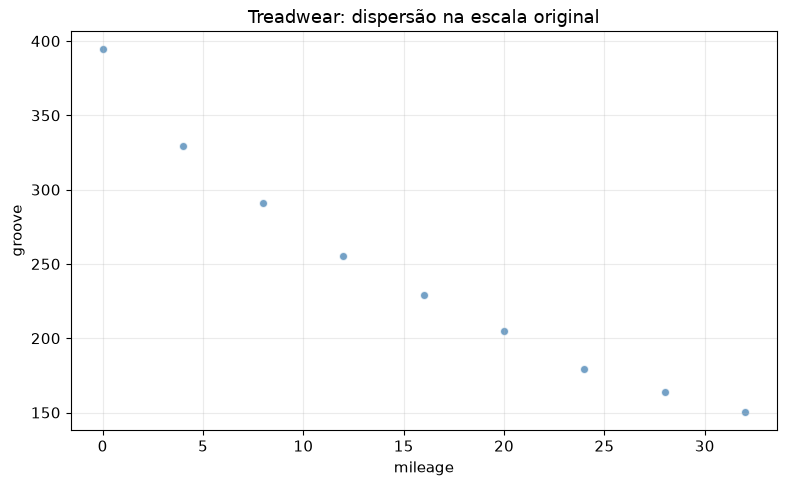

In [62]:
plotar_dispersao(
    df_treadwear,
    x_treadwear,
    y_treadwear,
    "Treadwear",
)

### Análise visual da associação

Observa-se associação negativa entre `mileage` e `groove`:
a medida dos sulcos diminui à medida que a quilometragem aumenta.

Entretanto, a redução é mais acentuada nas menores quilometragens
e se torna menos intensa nas maiores. Esse comportamento sugere
uma relação curvilínea, em vez de uma redução constante.

Os valores de mileage estão igualmente espaçados no intervalo
observado, sem concentração em uma região específica do eixo X.

Portanto, existe uma associação visual clara, mas uma reta
pode não representar adequadamente sua forma.

### Ajuste da regressão linear simples

O modelo foi ajustado por mínimos quadrados ordinários,
com intercepto. O método escolhe os coeficientes que minimizam
a soma dos quadrados dos resíduos:

$$
\sum_{i=1}^{n}
\left[groove_i-
(\hat{\beta}_0+\hat{\beta}_1\,mileage_i)\right]^2.
$$

Embora a dispersão sugira curvatura, o ajuste linear é realizado
como análise preliminar, conforme solicitado no exercício.

In [63]:
print(modelo_treadwear.summary())

print(
    f"\nEquação: groove estimado = "
    f"{modelo_treadwear.params['const']:.4f} "
    f"+ ({modelo_treadwear.params[x_treadwear]:.4f}) × mileage"
)

print(f"R²: {modelo_treadwear.rsquared:.4f}")
print(f"R² ajustado: {modelo_treadwear.rsquared_adj:.4f}")
print(
    "Erro padrão residual: "
    f"{np.sqrt(modelo_treadwear.mse_resid):.4f}"
)

                            OLS Regression Results                            
Dep. Variable:                 groove   R-squared:                       0.953
Model:                            OLS   Adj. R-squared:                  0.946
Method:                 Least Squares   F-statistic:                     140.7
Date:                Tue, 13 Oct 2026   Prob (F-statistic):           6.87e-06
Time:                        05:13:43   Log-Likelihood:                -38.148
No. Observations:                   9   AIC:                             80.30
Df Residuals:                       7   BIC:                             80.69
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        360.6367     11.689     30.854      0.0

### Interpretação do ajuste

A equação estimada é:

$$
\widehat{groove}
=360{,}6367-7{,}2806\,mileage.
$$

Segundo a reta ajustada, o aumento de uma unidade em mileage
está associado a uma redução média estimada de aproximadamente
7,28 unidades em groove, nas escalas registradas no arquivo.

O intercepto representa a medida prevista dos sulcos quando
mileage é igual a zero. Esse valor de X está presente na amostra,
mas a previsão não precisa coincidir com a observação correspondente,
pois a reta é ajustada considerando todos os pontos.

O R² é aproximadamente 0,9526, indicando que a reta explica
cerca de 95,26% da variação amostral de groove em torno de sua média.
O R² ajustado é aproximadamente 0,9458, também indicando elevada
capacidade explicativa na amostra.

Entretanto, esses indicadores não demonstram que a forma linear
seja adequada. Uma relação curvilínea pode apresentar R² elevado
quando aproximada por uma reta.

O erro padrão residual é aproximadamente 19,02 unidades de groove.
Esse indicador descreve a dispersão residual na amostra,
sem substituir uma avaliação da capacidade de prever dados novos.

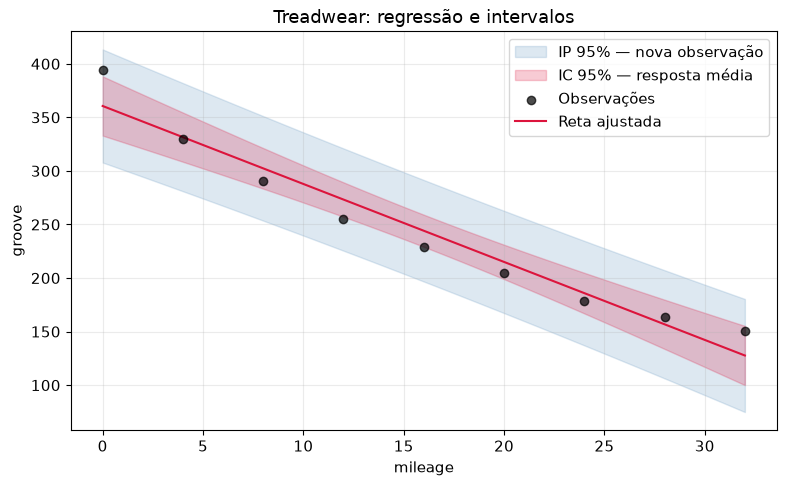

In [64]:
plotar_ajuste(
    df_treadwear,
    modelo_treadwear,
    x_treadwear,
    y_treadwear,
    "Treadwear",
)

### Intervalos de confiança e predição

O intervalo de confiança de 95% representa a incerteza
na estimação da resposta média para cada quilometragem.

O intervalo de predição de 95% representa a incerteza para
uma nova observação individual na mesma quilometragem.
Ele é mais amplo porque incorpora também a variabilidade
individual dos erros.

Os intervalos são pontuais e foram calculados sob as premissas
convencionais da regressão linear.

No gráfico, a reta tende a subestimar a resposta nos extremos
e superestimá-la na região intermediária, reforçando a suspeita
de curvatura. A presença das faixas não comprova a adequação
do modelo nem garante sua cobertura nominal se as premissas
forem inadequadas.

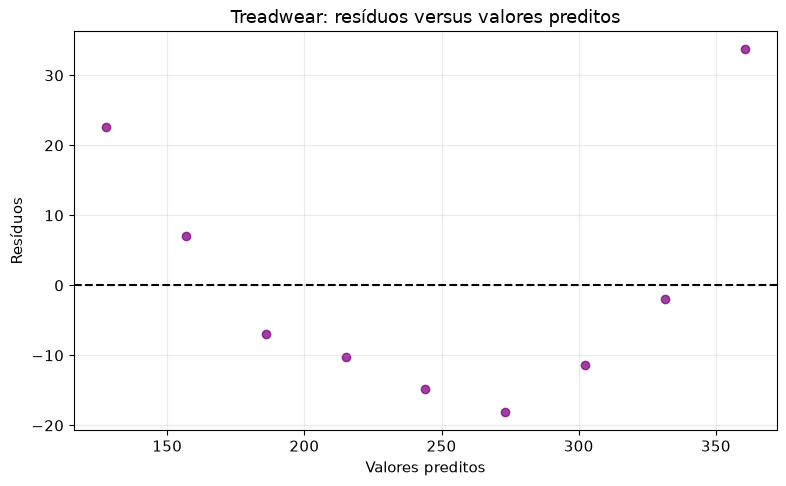

In [65]:
plotar_residuos(modelo_treadwear, "Treadwear")

### Resíduos versus valores preditos

Os resíduos apresentam um padrão em U: são positivos
nos extremos e predominantemente negativos na região intermediária.

Resíduos positivos indicam que a reta subestimou os valores
observados; resíduos negativos indicam que ela os superestimou.

Essa organização sistemática indica que a forma linear
não capturou adequadamente a relação média entre as variáveis.
Portanto, há evidência visual de violação da premissa de linearidade.

A média dos resíduos próxima de zero não elimina esse problema,
pois essa propriedade decorre do ajuste por mínimos quadrados
com intercepto.

### Distribuição dos resíduos

O histograma dos resíduos foi omitido conforme a orientação
do enunciado para Treadwear, devido ao pequeno tamanho amostral.

A distribuição será examinada pelo QQ-plot, reconhecendo
que nove observações fornecem evidência limitada.

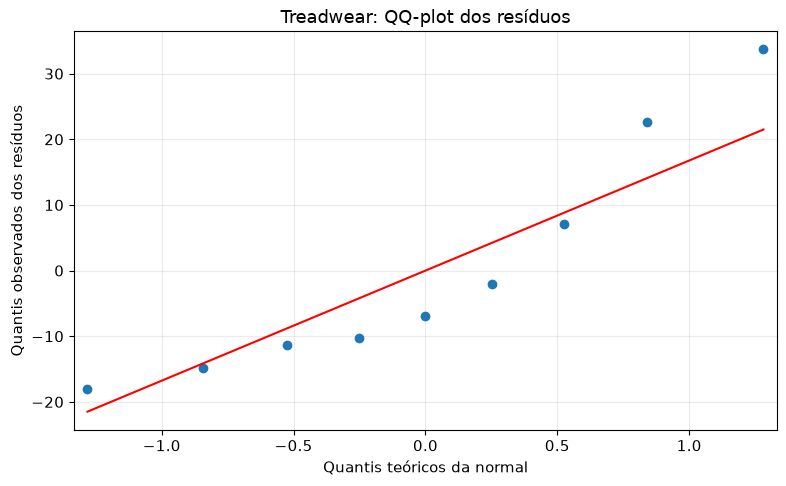

In [66]:
plotar_qq(modelo_treadwear, "Treadwear")

O QQ-plot apresenta desvios da reta de referência, especialmente
nos maiores resíduos positivos, sugerindo inadequação
da aproximação normal.

Entretanto, o tamanho amostral limita a força dessa avaliação.
Além disso, a curvatura não capturada pelo modelo pode contribuir
para a distribuição observada dos resíduos.

A premissa de normalidade diz respeito aos erros condicionais
a X, e não à distribuição bruta de mileage ou groove.

### Avaliação das premissas LINE

**L — Linearidade:** há evidências de violação. A dispersão
apresenta curvatura, confirmada pelo padrão em U dos resíduos.

**I — Independência:** não pode ser confirmada pelos gráficos
apresentados. É necessário conhecer o desenho da coleta,
especialmente se as observações correspondem a medições
sucessivas do mesmo pneu. O espaçamento regular de mileage
não demonstra independência dos erros.

**N — Normalidade:** há desvios no QQ-plot, especialmente
na cauda superior. Entretanto, a amostra pequena e a inadequação
da forma linear impedem uma conclusão forte sobre essa premissa.

**E — Variância constante:** a amostra pequena e a curvatura
residual dificultam distinguir uma mudança de variância
de um problema na especificação da média. Não há evidência
suficiente para afirmar que a premissa esteja satisfeita
ou claramente violada.

O modelo apresenta R² ajustado elevado, mas não representa
adequadamente a forma da associação. Assim, sua capacidade
explicativa na amostra não basta para considerá-lo satisfatório.

A exploração de transformações na etapa 3.2 será utilizada
para investigar uma representação mais próxima da linearidade.

## 3.1.2: Alligators
Neste conjunto, a variável preditora X é `length`, e a variável
resposta Y é `weight`.

O objetivo é avaliar se o comprimento dos animais permite estimar
seu peso por meio de uma regressão linear simples na escala original.

O modelo considerado é:

$$
weight_i = \beta_0 + \beta_1\,length_i + \varepsilon_i.
$$

Não serão realizadas transformações nesta etapa.

In [67]:
(
    df_alligators,
    modelo_alligators,
    x_alligators,
    y_alligators,
) = preparar_regressao("Alligators")

display(df_alligators.head())
display(df_alligators.describe())
display(df_alligators.isna().sum())

print(f"Número de observações: {len(df_alligators)}")

,length,weight
0,94,130
1,74,51
2,147,640
3,58,28
4,86,80


,length,weight
count,25.000000,25.000000
mean,84.960000,108.200000
std,20.235036,130.614892
min,58.000000,28.000000
25%,72.000000,44.000000
50%,85.000000,80.000000
75%,90.000000,102.000000
max,147.000000,640.000000


length    0
weight    0
dtype: int64

Número de observações: 25


O conjunto contém 25 observações, sem valores ausentes nas duas
variáveis analisadas.

A conferência inicial permite verificar o tamanho da amostra,
a amplitude das variáveis e a existência de problemas que poderiam
comprometer o ajuste. Nenhuma observação foi excluída.

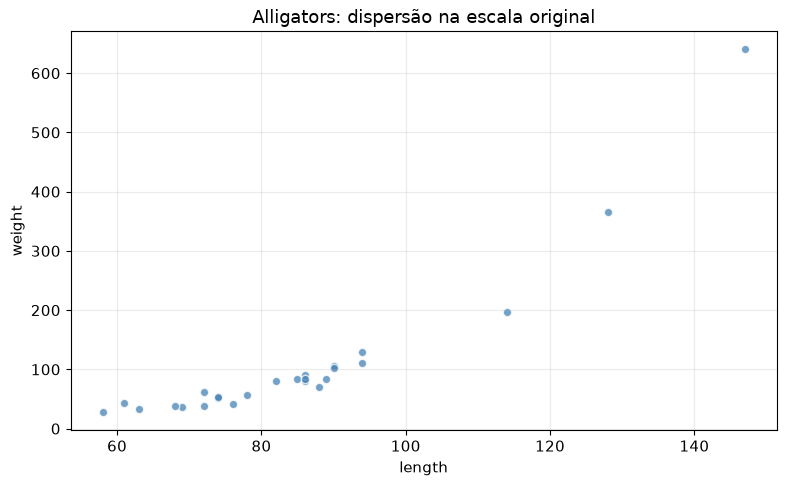

In [68]:
plotar_dispersao(
    df_alligators,
    x_alligators,
    y_alligators,
    "Alligators",
)

### Análise visual da associação

Observa-se associação positiva entre comprimento e peso:
animais maiores tendem a apresentar maior peso.

Entretanto, a tendência não parece estritamente linear.
O crescimento do peso torna-se mais acentuado nos maiores
comprimentos, sugerindo curvatura.

Há concentração de observações nos menores comprimentos e pesos,
enquanto poucas observações ocupam a região superior do gráfico.
Essas observações merecem atenção porque podem exercer influência
relevante sobre o ajuste.

Assim, existe associação visual clara, mas sua forma sugere que
uma reta na escala original pode não representar adequadamente
a resposta média.

### Ajuste da regressão linear simples

O modelo foi ajustado por mínimos quadrados ordinários, com intercepto.
O método escolhe os coeficientes que minimizam a soma dos quadrados
das diferenças entre os pesos observados e os pesos previstos.

O intercepto foi estimado livremente, sem impor que a reta passe
pela origem.

In [69]:
print(modelo_alligators.summary())

print(
    f"\nEquação: weight estimado = "
    f"{modelo_alligators.params['const']:.4f} "
    f"+ {modelo_alligators.params[x_alligators]:.4f} × length"
)

print(f"R²: {modelo_alligators.rsquared:.4f}")
print(f"R² ajustado: {modelo_alligators.rsquared_adj:.4f}")
print(
    "Erro padrão residual: "
    f"{np.sqrt(modelo_alligators.mse_resid):.4f}"
)

                            OLS Regression Results                            
Dep. Variable:                 weight   R-squared:                       0.836
Model:                            OLS   Adj. R-squared:                  0.829
Method:                 Least Squares   F-statistic:                     117.4
Date:                Tue, 13 Oct 2026   Prob (F-statistic):           1.65e-10
Time:                        05:13:44   Log-Likelihood:                -134.16
No. Observations:                  25   AIC:                             272.3
Df Residuals:                      23   BIC:                             274.8
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       -393.2640     47.534     -8.273      0.0

### Interpretação do ajuste

A equação estimada é:

$$
\widehat{weight}
= -393{,}2640 + 5{,}9024\,length.
$$

Segundo a reta ajustada, o aumento de uma unidade em `length`
está associado a um aumento médio estimado de aproximadamente
5,90 unidades em `weight`, nas escalas registradas no arquivo.

O intercepto negativo não deve ser interpretado como um peso
fisicamente possível para comprimento zero. Esse comprimento
está fora do intervalo observado, e a interpretação representaria
uma extrapolação.

O R² é aproximadamente 0,8361, enquanto o R² ajustado é 0,8290.
Esses valores indicam que a reta captura uma parcela substancial
da variabilidade amostral do peso.

Entretanto, esse resultado não demonstra que a forma linear
seja adequada. A curvatura observada na dispersão precisa ser
avaliada por meio dos resíduos.

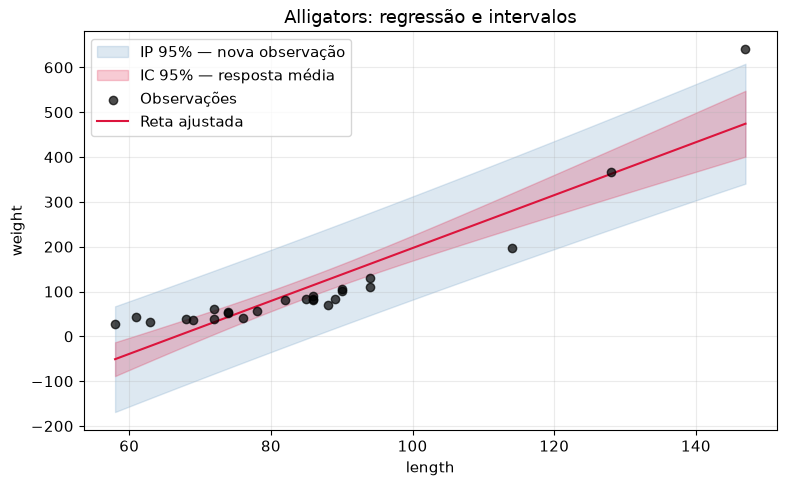

In [70]:
plotar_ajuste(
    df_alligators,
    modelo_alligators,
    x_alligators,
    y_alligators,
    "Alligators",
)

### Intervalos de confiança e predição

O intervalo de confiança de 95% representa a incerteza sobre
o peso médio estimado para cada comprimento.

O intervalo de predição de 95% representa a incerteza sobre
o peso de um novo animal com esse comprimento. Ele é mais amplo
porque incorpora também a variabilidade individual dos erros.

As faixas apresentadas são intervalos pontuais, calculados sob
as premissas convencionais da regressão. Sua presença no gráfico
não demonstra que essas premissas sejam válidas.

Eventuais previsões ou limites negativos são incompatíveis
com a natureza física do peso e evidenciam uma limitação
do modelo linear na escala original.

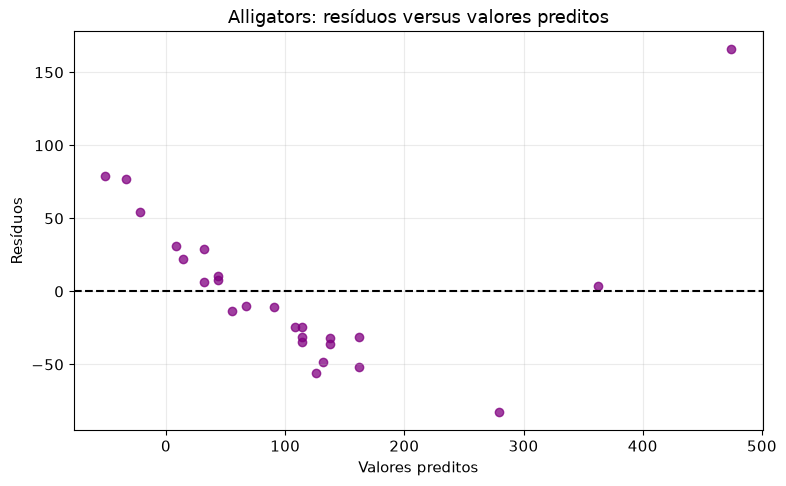

In [71]:
plotar_residuos(modelo_alligators, "Alligators")

### Resíduos versus valores preditos

Os resíduos apresentam um padrão sistemático: tendem a ser
positivos nas menores previsões, negativos em uma região
intermediária e novamente positivos nas maiores previsões.

Esse comportamento indica curvatura não capturada pela reta
e constitui evidência contra a premissa de linearidade.

Também há um resíduo positivo elevado. Essa observação merece
investigação, mas não deve ser excluída apenas por apresentar
grande diferença entre valor observado e previsto.

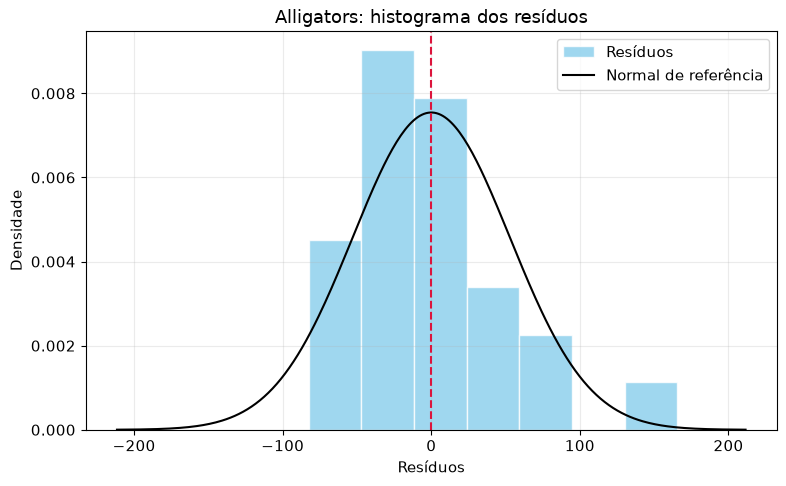

In [72]:
plotar_histograma(modelo_alligators, "Alligators")

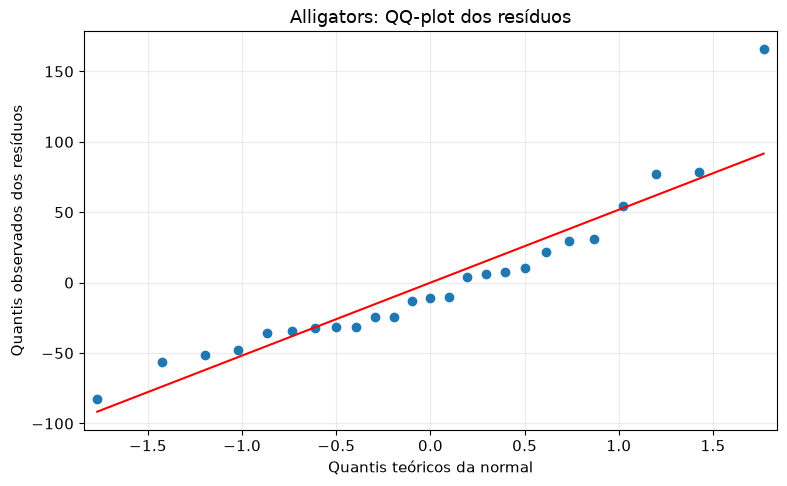

In [73]:
plotar_qq(modelo_alligators, "Alligators")

### Distribuição dos resíduos

A distribuição dos resíduos apresenta assimetria à direita,
com um resíduo positivo elevado.

No QQ-plot, os pontos não seguem perfeitamente a reta de referência,
e o maior resíduo positivo apresenta um desvio importante.
Isso sugere inadequação da aproximação normal, especialmente
na cauda superior.

A avaliação deve considerar que a amostra contém 25 observações
e que a forma incorreta da relação média pode contribuir
para os desvios observados.

### Avaliação das premissas LINE

**L — Linearidade:** há evidências de violação. A dispersão
apresenta curvatura, confirmada pelo padrão sistemático
dos resíduos.

**I — Independência:** não pode ser confirmada pelos gráficos
apresentados. É necessário conhecer o desenho da coleta,
incluindo possíveis relações entre os animais amostrados.

**N — Normalidade:** há indícios de inadequação, sobretudo
na cauda superior do QQ-plot. A assimetria e o resíduo positivo
elevado tornam essa premissa questionável.

**E — Variância constante:** não há uma nuvem residual homogênea,
mas a curvatura dificulta separar mudanças de variância
de problemas na especificação da média. Portanto, não é possível
afirmar com segurança que essa premissa esteja satisfeita.

Apesar do R² ajustado relativamente elevado, o modelo linear
na escala original apresenta limitações importantes.
A análise justifica explorar transformações de escala na etapa 3.2.

## 3.1.3: ConcPatog
Neste conjunto, a variável preditora X é `CPatog1`, e a variável
resposta Y é `CPatog2`.

O objetivo é avaliar se a concentração do patógeno 1 permite
estimar a concentração do patógeno 2 por meio de uma regressão
linear simples na escala original.

As observações foram obtidas em diferentes estações, estágios
de tratamento e meses. Nesta etapa, o modelo utiliza somente
as duas concentrações:

$$
CPatog2_i = \beta_0 + \beta_1\,CPatog1_i + \varepsilon_i.
$$

In [74]:
(
    df_patogenos,
    modelo_patogenos,
    x_patogenos,
    y_patogenos,
) = preparar_regressao("ConcPatog")

display(df_patogenos.head())
display(df_patogenos.describe())
display(df_patogenos.isna().sum())

print(f"Número de observações: {len(df_patogenos)}")

,CPatog1,CPatog2
0,5210,7272
1,5770,12800
2,10700,179000
3,16700,190000
4,5610,82875


,CPatog1,CPatog2
count,105.000000,1.050000e+02
mean,5149.133333,1.498282e+05
std,34527.251492,3.986516e+05
min,0.000000,4.000000e+00
25%,38.000000,1.190000e+03
50%,359.000000,1.390000e+04
75%,1700.000000,9.680000e+04
max,354000.000000,2.877485e+06


CPatog1    0
CPatog2    0
dtype: int64

Número de observações: 105


O conjunto contém 105 observações, sem valores ausentes
nas duas concentrações analisadas.

Os valores apresentam grande amplitude. Todas as observações
foram mantidas, incluindo concentrações iguais a zero em CPatog1
e valores elevados em ambas as variáveis.

Valores extremos podem corresponder a características reais
da coleta e não devem ser eliminados sem investigação.

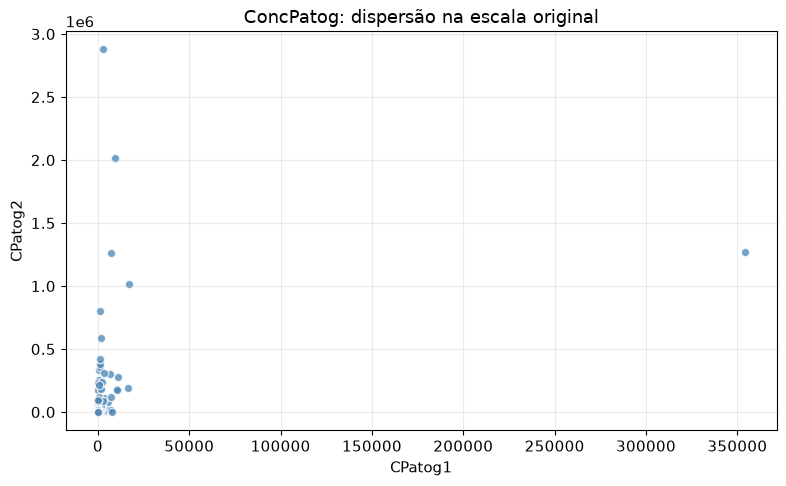

In [75]:
plotar_dispersao(
    df_patogenos,
    x_patogenos,
    y_patogenos,
    "ConcPatog",
)

### Análise visual da associação

A maioria dos pontos está concentrada na região de menores
concentrações. Poucas observações apresentam valores muito elevados,
ampliando os eixos e dificultando a visualização da estrutura
da maior parte dos dados.

Não se observa uma associação linear clara e uniforme
na escala original. Para valores relativamente baixos de CPatog1,
há grande variação em CPatog2, incluindo concentrações muito elevadas.

Esse padrão sugere que uma reta pode fornecer uma representação
limitada da relação e que observações extremas podem influenciar
fortemente o ajuste.

### Ajuste da regressão linear simples

Foi ajustado um modelo por mínimos quadrados ordinários
com intercepto, mantendo as concentrações em suas escalas originais.

O ajuste minimiza a soma dos quadrados dos resíduos. Por elevar
as diferenças ao quadrado, esse critério atribui grande peso
a observações com resíduos elevados.

In [76]:
print(modelo_patogenos.summary())

print(
    f"\nEquação: CPatog2 estimado = "
    f"{modelo_patogenos.params['const']:.4f} "
    f"+ {modelo_patogenos.params[x_patogenos]:.4f} × CPatog1"
)

print(f"R²: {modelo_patogenos.rsquared:.4f}")
print(f"R² ajustado: {modelo_patogenos.rsquared_adj:.4f}")
print(
    "Erro padrão residual: "
    f"{np.sqrt(modelo_patogenos.mse_resid):.4f}"
)

                            OLS Regression Results                            
Dep. Variable:                CPatog2   R-squared:                       0.095
Model:                            OLS   Adj. R-squared:                  0.086
Method:                 Least Squares   F-statistic:                     10.81
Date:                Tue, 13 Oct 2026   Prob (F-statistic):            0.00138
Time:                        05:13:44   Log-Likelihood:                -1497.3
No. Observations:                 105   AIC:                             2999.
Df Residuals:                     103   BIC:                             3004.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       1.315e+05   3.76e+04      3.497      0.0

### Interpretação do ajuste

A equação estimada é:

$$
\widehat{CPatog2}
= 131506{,}0008 + 3{,}5583\,CPatog1.
$$

Segundo a reta ajustada, o aumento de uma unidade em CPatog1
está associado a um aumento médio estimado de aproximadamente
3,56 unidades em CPatog2, nas escalas registradas no arquivo.

O intercepto corresponde à resposta prevista quando CPatog1
é igual a zero. Embora esse valor de X esteja presente nos dados,
o intercepto deve ser interpretado como uma estimativa do modelo,
e não como uma relação causal entre os patógenos.

O R² é aproximadamente 0,0950, enquanto o R² ajustado é 0,0862.
Portanto, a reta captura uma parcela pequena da variabilidade
amostral da concentração do patógeno 2.

O erro padrão residual é aproximadamente 381084,36 unidades
da resposta, indicando elevada dispersão em torno da reta.

Esses resultados não permitem afirmar que o modelo forneça
estimativas com razoável acurácia. Também não demonstram ausência
de associação: podem existir relações não lineares ou diferenças
entre grupos que não foram representadas pelo modelo.

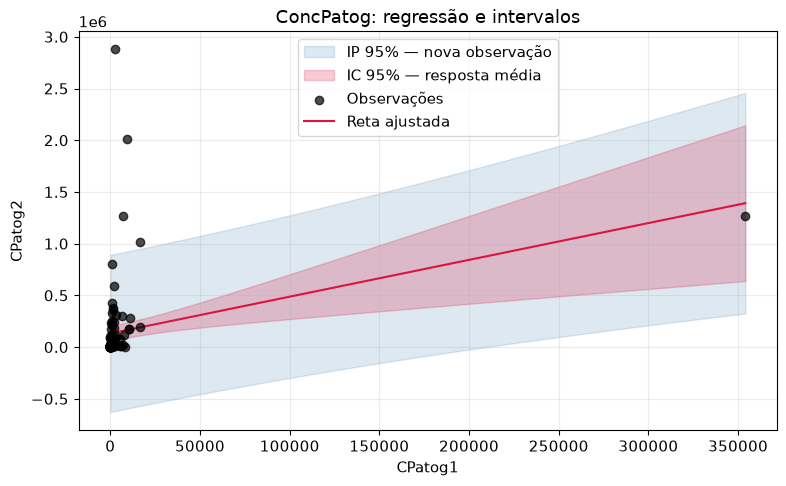

In [77]:
plotar_ajuste(
    df_patogenos,
    modelo_patogenos,
    x_patogenos,
    y_patogenos,
    "ConcPatog",
)

### Intervalos de confiança e predição

O intervalo de confiança representa a incerteza na estimação
da concentração média de CPatog2 para cada valor de CPatog1.

O intervalo de predição representa a incerteza para uma nova
observação individual e é mais amplo, pois inclui também
a variabilidade residual.

A grande variabilidade dos dados produz intervalos de predição
amplos. Limites inferiores negativos são incompatíveis
com concentrações físicas e evidenciam uma limitação
do modelo normal aditivo na escala original.

Além disso, a validade dos intervalos depende das premissas
do modelo, que serão examinadas pelos resíduos.

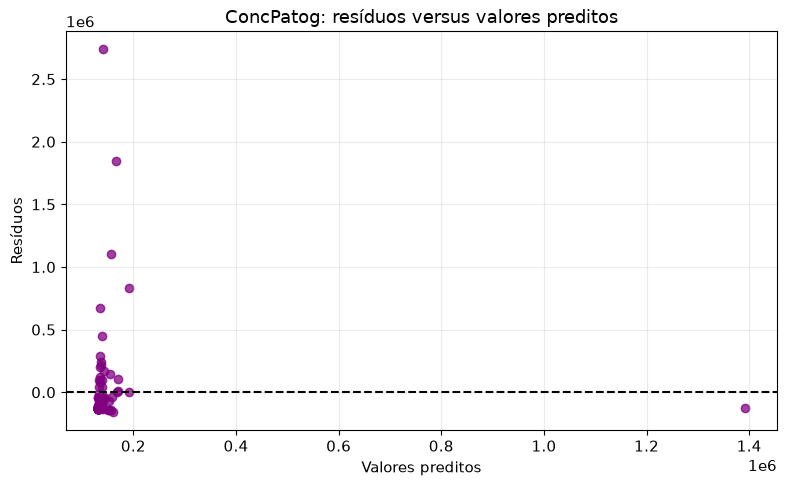

In [78]:
plotar_residuos(modelo_patogenos, "ConcPatog")

### Resíduos versus valores preditos

Há forte concentração de observações em uma região do gráfico,
acompanhada de resíduos positivos extremamente elevados.

O padrão não corresponde a uma nuvem aproximadamente homogênea
e simétrica ao redor de zero. A reta subestima fortemente algumas
concentrações observadas de CPatog2.

A presença de observações extremas e a distribuição desigual
dos pontos dificultam identificar uma eventual curvatura.
Assim, o gráfico não sustenta a adequação da relação linear,
mas também não permite atribuir toda a inadequação
a uma única causa.

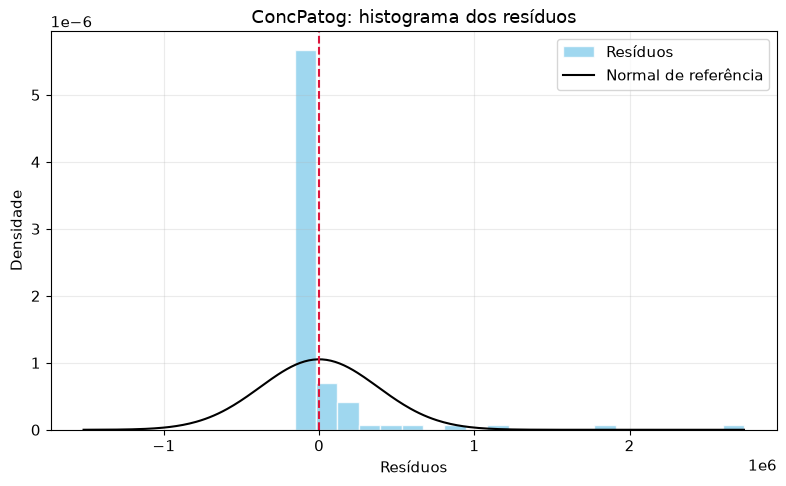

In [79]:
plotar_histograma(modelo_patogenos, "ConcPatog")

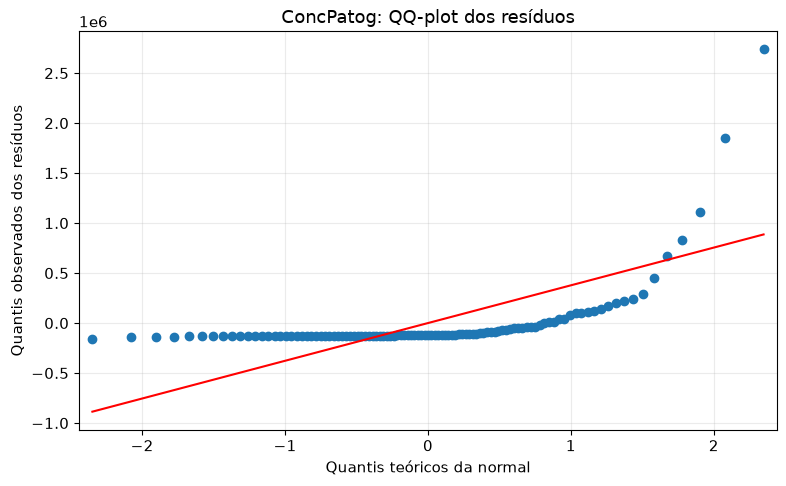

In [80]:
plotar_qq(modelo_patogenos, "ConcPatog")

### Distribuição dos resíduos

Os resíduos apresentam forte assimetria à direita, com uma
cauda positiva extensa.

O QQ-plot mostra desvios acentuados da reta de referência,
principalmente nos maiores quantis. Esse comportamento fornece
evidência visual forte contra a aproximação normal dos erros
no modelo ajustado.

A concentração de muitos resíduos em uma região e a presença
de poucos valores positivos muito elevados também dificultam
a representação da distribuição por uma curva normal.

### Avaliação das premissas LINE

**L — Linearidade:** não há evidência visual suficiente para
considerar a forma linear adequada. A dispersão não apresenta
uma tendência linear uniforme, e o modelo deixa grande
variabilidade sem explicação. O baixo R², isoladamente,
não demonstra violação de linearidade.

**I — Independência:** não pode ser confirmada. As observações
envolvem diferentes estações, estágios de tratamento e meses,
podendo existir dependências entre medições relacionadas.
Essa questão exige examinar a estrutura da coleta.

**N — Normalidade:** há evidências fortes de violação.
A distribuição dos resíduos é assimétrica, e o QQ-plot apresenta
desvios acentuados, sobretudo na cauda superior.

**E — Variância constante:** a distribuição dos resíduos
não apresenta amplitude homogênea entre as regiões observadas,
levantando suspeita de heterocedasticidade. Entretanto,
a distribuição desigual de X e as observações extremas
limitam a separação entre mudança de variância e outros
problemas do modelo.

A regressão linear simples na escala original apresenta baixo
poder explicativo e problemas importantes no diagnóstico
dos resíduos. Portanto, não há suporte para considerá-la
satisfatória para estimar CPatog2 com razoável acurácia.

A etapa 3.2 investigará se transformações de escala produzem
uma representação mais adequada, sem pressupor que elas
resolverão todas as limitações.

## 3.2: Exploração das transformações de escala

Foram consideradas nove combinações:

- Raiz quadrada somente em X, somente em Y e em ambas.
- Quadrado somente em X, somente em Y e em ambas.
- Logaritmo decimal somente em X, somente em Y e em ambas.

A escolha considera a proximidade da associação com uma reta
e o diagnóstico dos resíduos. O R² ajustado é apresentado
como informação complementar.

Quando Y é transformada, o R² passa a descrever a variabilidade
da resposta nessa nova escala. Portanto, seus valores não devem
ser usados isoladamente para comparar a capacidade de previsão
na escala original.

Transformações sem domínio válido serão registradas como inviáveis,
mantendo todas as observações e sem acrescentar constantes.

In [81]:
def transformar(serie, tipo):
    serie = serie.astype(float)

    if tipo == "original":
        return serie.copy()

    if tipo == "raiz":
        if (serie < 0).any():
            raise ValueError("Raiz quadrada exige valores não negativos.")
        return np.sqrt(serie)

    if tipo == "quadrado":
        return serie ** 2

    if tipo == "log10":
        if (serie <= 0).any():
            raise ValueError("Log10 exige valores estritamente positivos.")
        return np.log10(serie)

    raise ValueError(f"Transformação desconhecida: {tipo}")


combinacoes = [
    ("raiz em X", "raiz", "original"),
    ("raiz em Y", "original", "raiz"),
    ("raiz em ambas", "raiz", "raiz"),
    ("quadrado em X", "quadrado", "original"),
    ("quadrado em Y", "original", "quadrado"),
    ("quadrado em ambas", "quadrado", "quadrado"),
    ("log10 em X", "log10", "original"),
    ("log10 em Y", "original", "log10"),
    ("log10 em ambas", "log10", "log10"),
]

In [82]:
def explorar_transformacoes(nome):
    config = configuracoes[nome]

    dados = pd.read_csv(
        pasta_dados / config["arquivo"],
        sep=r"\s+",
    )

    x = pd.to_numeric(dados[config["x"]], errors="raise")
    y = pd.to_numeric(dados[config["y"]], errors="raise")

    if not np.isfinite(np.column_stack([x, y])).all():
        raise ValueError("Há dados ausentes ou não finitos.")

    fig, axes = plt.subplots(3, 3, figsize=(15, 12))
    resultados = []

    for ax, (rotulo, tx, ty) in zip(axes.flat, combinacoes):
        try:
            xt = transformar(x, tx)
            yt = transformar(y, ty)

            matriz = sm.add_constant(
                pd.DataFrame({"X": xt}),
                has_constant="add",
            )
            ajuste = sm.OLS(yt, matriz).fit()

            ordem = np.argsort(xt.to_numpy())

            ax.scatter(xt, yt, alpha=0.7)
            ax.plot(
                xt.to_numpy()[ordem],
                ajuste.fittedvalues.to_numpy()[ordem],
                color="crimson",
            )

            ax.set_title(rotulo)
            ax.set_xlabel(f"{tx}({config['x']})")
            ax.set_ylabel(f"{ty}({config['y']})")

            resultados.append({
                "combinação": rotulo,
                "situação": "válida",
                "R² ajustado": ajuste.rsquared_adj,
            })

        except ValueError as erro:
            ax.text(
                0.5, 0.5,
                f"Inviável\n{erro}",
                ha="center",
                va="center",
                transform=ax.transAxes,
                wrap=True,
            )
            ax.set_title(rotulo)
            ax.set_xticks([])
            ax.set_yticks([])

            resultados.append({
                "combinação": rotulo,
                "situação": str(erro),
                "R² ajustado": np.nan,
            })

    fig.suptitle(f"{nome}: exploração das transformações")
    plt.tight_layout()
    plt.show()

    return pd.DataFrame(resultados)

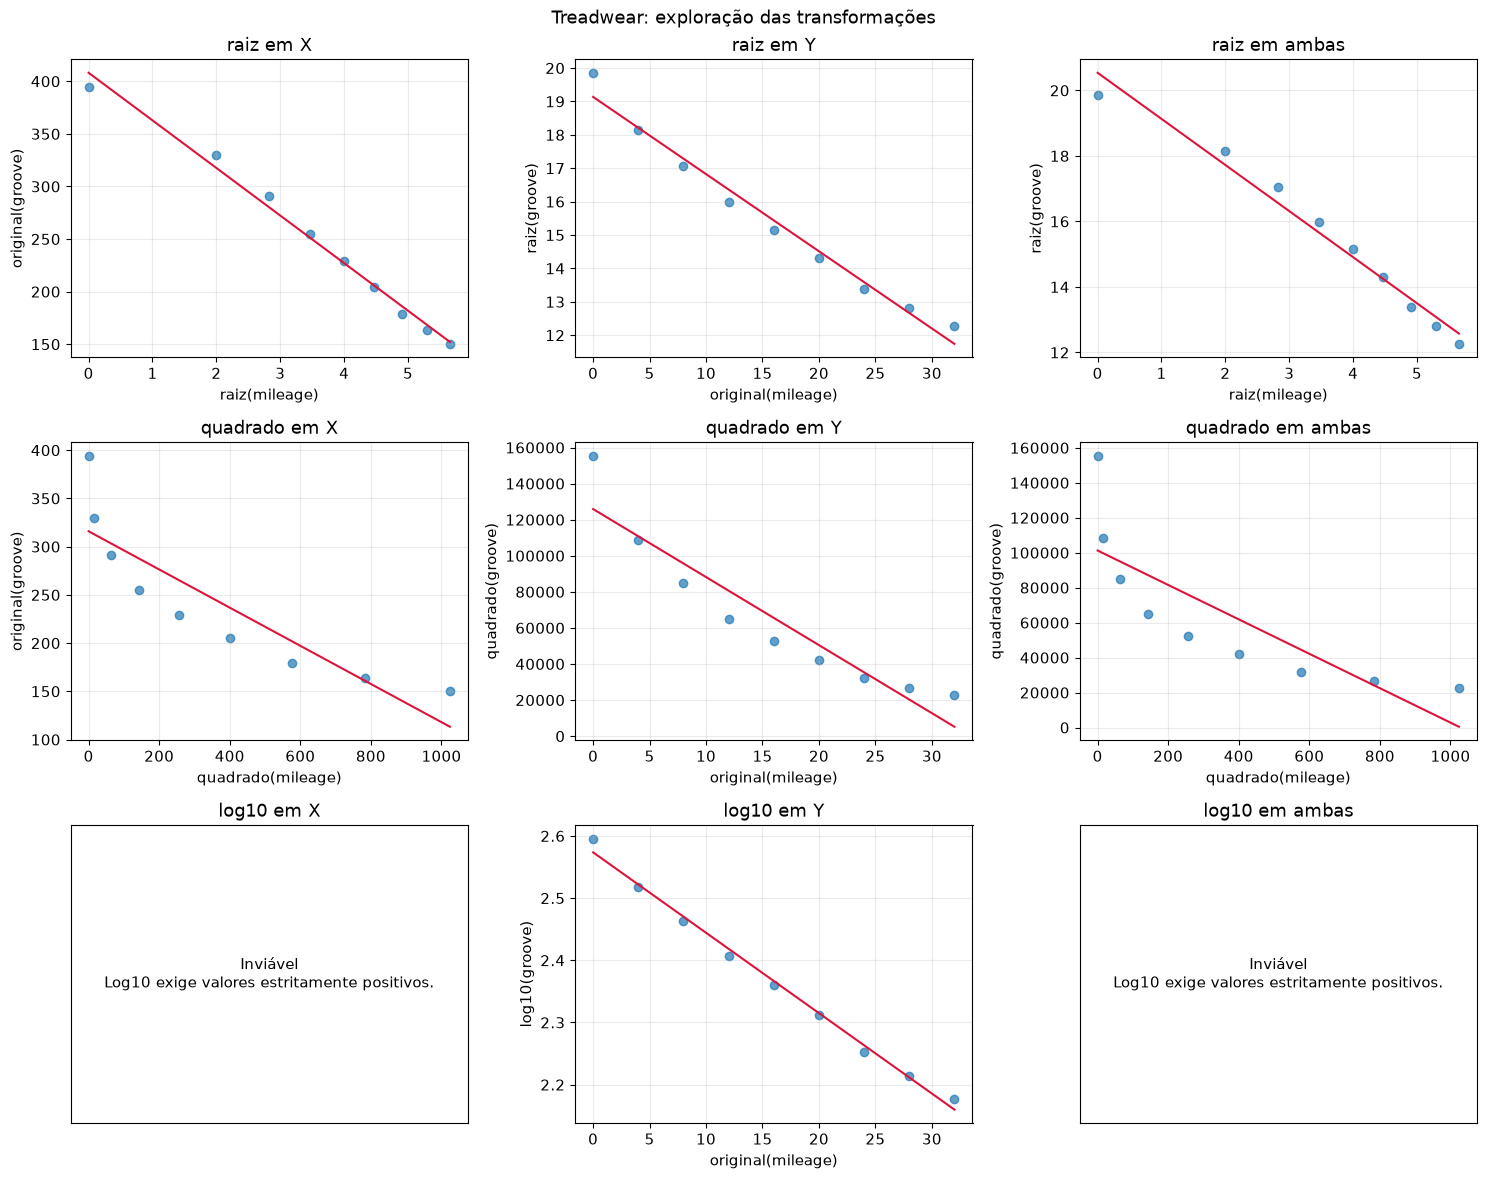

,combinação,situação,R² ajustado
0,raiz em X,válida,0.988196
1,raiz em Y,válida,0.974112
2,raiz em ambas,válida,0.971480
3,quadrado em X,válida,0.746738
4,quadrado em Y,válida,0.864237
5,quadrado em ambas,válida,0.615700
6,log10 em X,Log10 exige valores estritamente positivos.,NaN
7,log10 em Y,válida,0.991864
8,log10 em ambas,Log10 exige valores estritamente positivos.,NaN


In [83]:
exploracao_treadwear = explorar_transformacoes("Treadwear")
display(exploracao_treadwear)

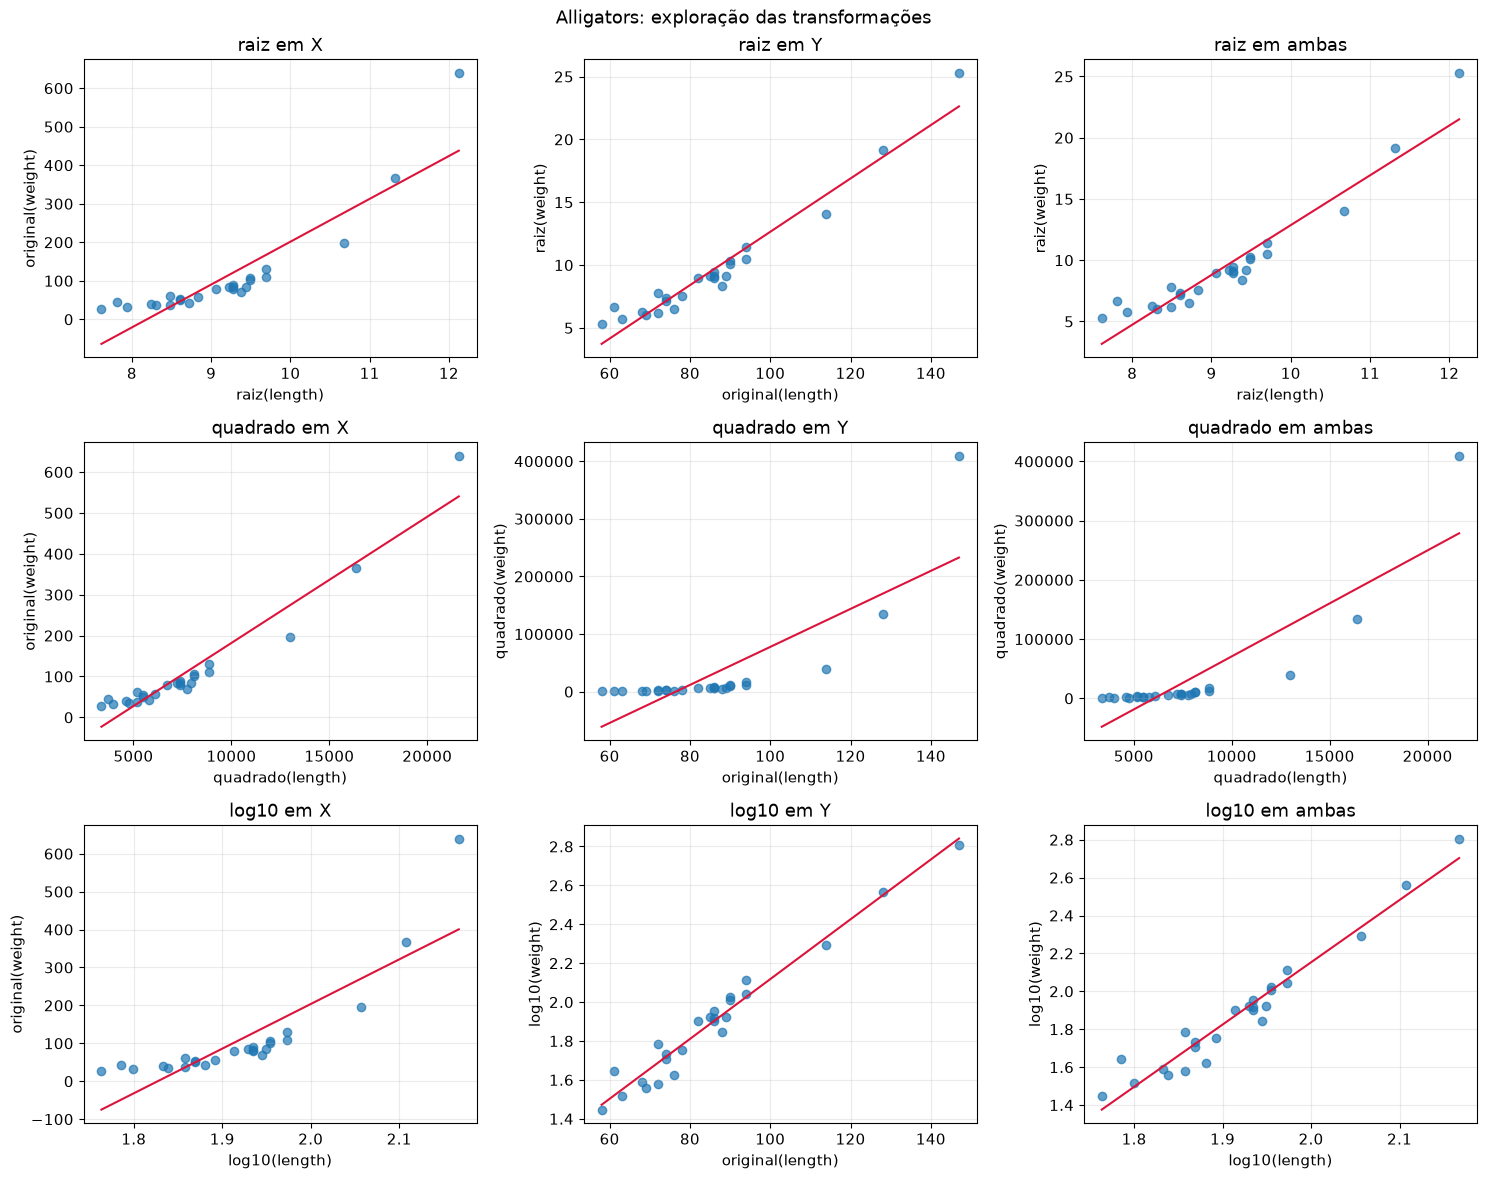

,combinação,situação,R² ajustado
0,raiz em X,válida,0.770019
1,raiz em Y,válida,0.938371
2,raiz em ambas,válida,0.901437
3,quadrado em X,válida,0.919917
4,quadrado em Y,válida,0.618648
5,quadrado em ambas,válida,0.742899
6,log10 em X,válida,0.704550
7,log10 em Y,válida,0.958331
8,log10 em ambas,válida,0.942547


In [84]:
exploracao_alligators = explorar_transformacoes("Alligators")
display(exploracao_alligators)

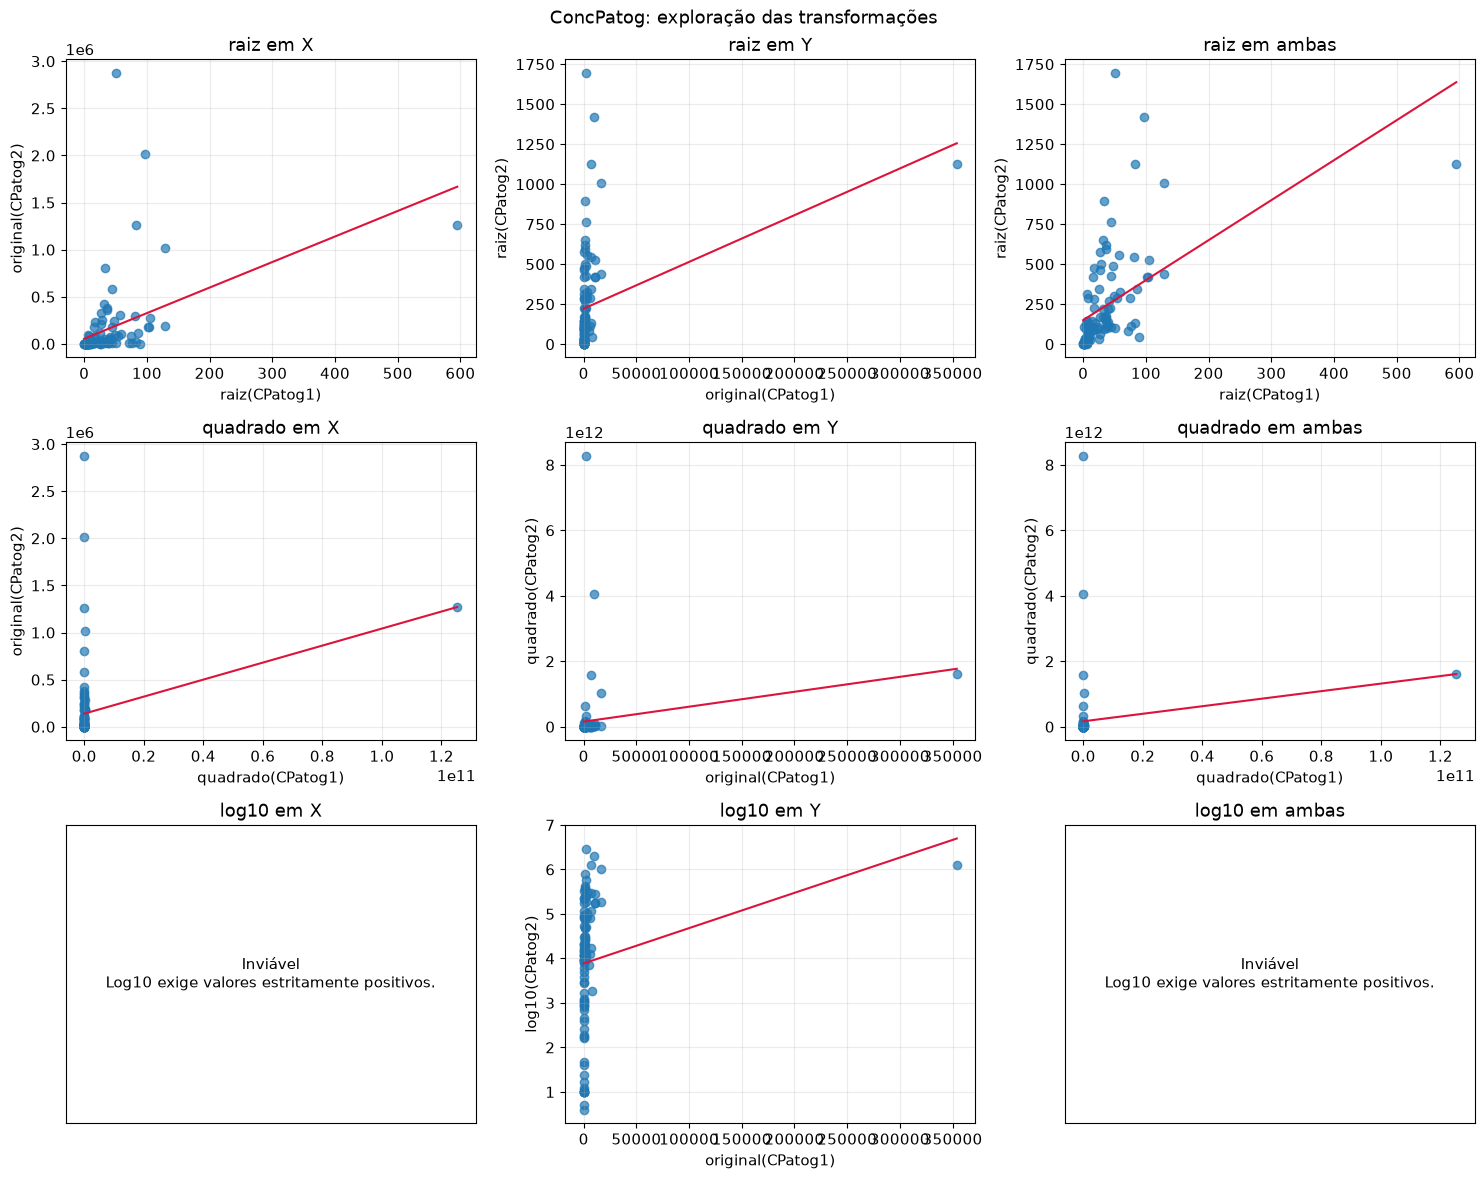

,combinação,situação,R² ajustado
0,raiz em X,válida,0.175907
1,raiz em Y,válida,0.099022
2,raiz em ambas,válida,0.256005
3,quadrado em X,válida,0.067804
4,quadrado em Y,válida,0.019681
5,quadrado em ambas,válida,0.013834
6,log10 em X,Log10 exige valores estritamente positivos.,NaN
7,log10 em Y,válida,0.025953
8,log10 em ambas,Log10 exige valores estritamente positivos.,NaN


In [85]:
exploracao_patogenos = explorar_transformacoes("ConcPatog")
display(exploracao_patogenos)

## Conclusões para cada dataset

### Treadwear
Selecionou-se o logaritmo decimal somente na variável resposta.

Essa transformação torna a associação visual mais próxima de uma reta.
A escolha foi fundamentada na forma da dispersão, e não na comparação
direta das magnitudes dos resíduos entre escalas diferentes.
Ainda há curvatura residual, de modo que a transformação não elimina
todas as limitações do modelo.

As transformações com logaritmo de mileage são inviáveis, pois
o conjunto contém uma observação com mileage igual a zero.

### Alligators
Selecionou-se o logaritmo decimal em ambas as variáveis.

O logaritmo somente em weight apresentou R² ajustado superior,
mas a combinação log-log foi escolhida por reduzir mais claramente
a curvatura da relação. Como essas duas alternativas utilizam
a mesma resposta transformada, seus R² são comparáveis quanto
ao ajuste amostral, embora esse indicador não substitua
o diagnóstico dos resíduos.

A transformação log-log também corresponde a uma relação de potência
entre peso e comprimento, uma representação plausível para
a relação entre tamanho corporal e massa.

### ConcPatog
Selecionou-se a raiz quadrada em ambas as variáveis.

Essa transformação permite manter as observações com CPatog1 igual
a zero e reduz a concentração visual dos dados nas menores escalas.
Entre as alternativas avaliadas, oferece uma representação mais
informativa da associação.

Entretanto, permanecem grande dispersão e observações extremas.
O R² ajustado de aproximadamente 0,2560 indica que o poder explicativo
continua limitado na escala transformada. A combinação escolhida
constitui uma melhora parcial, sem demonstrar que todas as premissas
foram satisfeitas.

In [86]:
def preparar_regressao_transformada(nome, tx, ty):
    config = configuracoes[nome]

    dados = pd.read_csv(
        pasta_dados / config["arquivo"],
        sep=r"\s+",
    )

    x_original = pd.to_numeric(
        dados[config["x"]], errors="raise"
    )
    y_original = pd.to_numeric(
        dados[config["y"]], errors="raise"
    )

    if not np.isfinite(
        np.column_stack([x_original, y_original])
    ).all():
        raise ValueError("Existem valores ausentes ou não finitos.")

    def nome_variavel(coluna, tipo):
        if tipo == "original":
            return coluna
        return f"{tipo}({coluna})"

    x_col = nome_variavel(config["x"], tx)
    y_col = nome_variavel(config["y"], ty)

    df = pd.DataFrame({
        x_col: transformar(x_original, tx),
        y_col: transformar(y_original, ty),
    })

    if not np.isfinite(df.to_numpy()).all():
        raise ValueError("A transformação gerou valores não finitos.")

    if len(df) < 3 or df[x_col].nunique() < 2:
        raise ValueError("Dados insuficientes para a regressão.")

    X = sm.add_constant(df[[x_col]], has_constant="add")
    modelo = sm.OLS(df[y_col], X).fit()

    return df, modelo, x_col, y_col

In [87]:
def plotar_dispersao(
    df, x_col, y_col, nome, escala="original"
):
    fig, ax = plt.subplots()

    ax.scatter(
        df[x_col],
        df[y_col],
        color="steelblue",
        alpha=0.75,
        edgecolor="white",
    )

    ax.set(
        xlabel=x_col,
        ylabel=y_col,
        title=f"{nome}: dispersão na escala {escala}",
    )

    plt.tight_layout()
    plt.show()

## 3.3: Análise das combinações escolhidas

Nesta etapa, repetimos os procedimentos da análise preliminar
utilizando as transformações selecionadas em 3.2.

As combinações escolhidas foram:

- Treadwear: logaritmo decimal somente em groove.
- Alligators: logaritmo decimal em length e weight.
- ConcPatog: raiz quadrada em CPatog1 e CPatog2.

Os coeficientes, os resíduos e os intervalos serão interpretados
nas escalas utilizadas no ajuste.

A escolha de uma transformação não garante que todas as premissas
LINE sejam satisfeitas. Por isso, o diagnóstico será realizado
novamente para cada modelo.

### 3.3.1: Treadwear

Foi aplicado logaritmo decimal à variável resposta groove,
mantendo mileage na escala original.

O modelo considerado é:

$$
\log_{10}(groove_i)
=\beta_0+\beta_1\,mileage_i+\varepsilon_i.
$$

A transformação comprime a escala da resposta e busca reduzir
a curvatura observada na análise original.

Como groove é estritamente positivo, a transformação permite
manter todas as nove observações.

,mileage,log10(groove)
0,0.0,2.595860
1,4.0,2.517855
2,8.0,2.463893
3,12.0,2.406830
4,16.0,2.360461


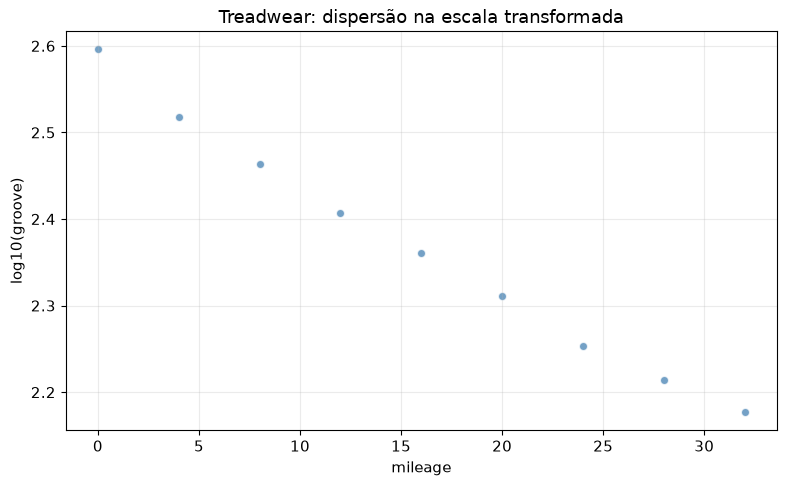

In [88]:
(
    df_treadwear_t,
    modelo_treadwear_t,
    x_treadwear_t,
    y_treadwear_t,
) = preparar_regressao_transformada(
    "Treadwear",
    tx="original",
    ty="log10",
)

display(df_treadwear_t.head())

plotar_dispersao(
    df_treadwear_t,
    x_treadwear_t,
    y_treadwear_t,
    "Treadwear",
    escala="transformada",
)

A associação continua negativa e torna-se visualmente mais próxima
de uma reta. Entretanto, ainda existem desvios sistemáticos
que devem ser examinados nos resíduos.

A transformação melhora a representação da tendência,
mas não demonstra, por si só, adequação completa do modelo.

In [89]:
print(modelo_treadwear_t.summary())

print(f"R²: {modelo_treadwear_t.rsquared:.4f}")
print(f"R² ajustado: {modelo_treadwear_t.rsquared_adj:.4f}")
print(
    "Erro padrão residual na escala log10: "
    f"{np.sqrt(modelo_treadwear_t.mse_resid):.6f}"
)

                            OLS Regression Results                            
Dep. Variable:          log10(groove)   R-squared:                       0.993
Model:                            OLS   Adj. R-squared:                  0.992
Method:                 Least Squares   F-statistic:                     976.3
Date:                Tue, 13 Oct 2026   Prob (F-statistic):           8.88e-09
Time:                        05:13:46   Log-Likelihood:                 27.570
No. Observations:                   9   AIC:                            -51.14
Df Residuals:                       7   BIC:                            -50.75
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          2.5736      0.008    326.576      0.0

#### Interpretação do ajuste

A equação estimada é:

$$
\widehat{\log_{10}(groove)}
=2{,}573609-0{,}012930\,mileage.
$$

O R² ajustado é aproximadamente 0,9919, indicando que a reta
captura uma parcela elevada da variabilidade de log10(groove).

Esse indicador descreve a resposta transformada. Portanto,
não deve ser interpretado como demonstração direta de melhor
acurácia preditiva na escala original.

Na retrotransformação da reta, uma unidade adicional de mileage
corresponde ao fator:

$$
10^{-0{,}012930}\approx0{,}9707.
$$

Assim, a resposta retrotransformada diminui aproximadamente 2,93%
por unidade adicional de mileage.

A retrotransformação da previsão logarítmica não fornece
automaticamente a média aritmética condicional de groove.

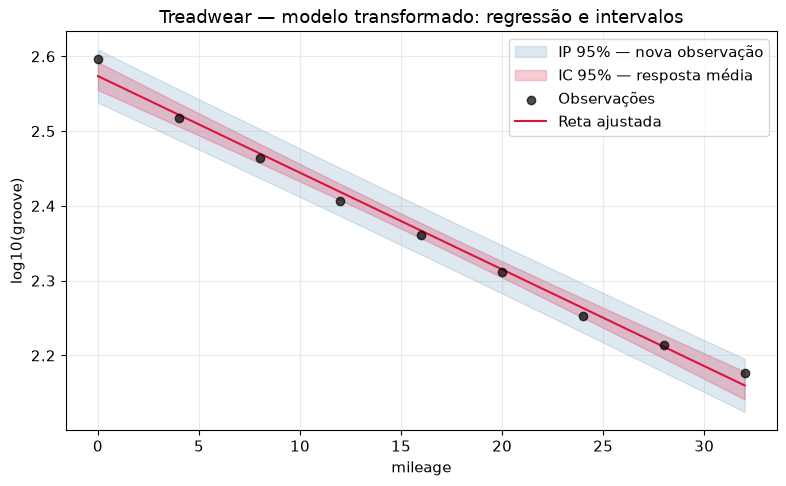

In [90]:
plotar_ajuste(
    df_treadwear_t,
    modelo_treadwear_t,
    x_treadwear_t,
    y_treadwear_t,
    "Treadwear — modelo transformado",
)

O intervalo de confiança representa a incerteza sobre a média
de log10(groove) para cada mileage.

O intervalo de predição representa a incerteza sobre uma nova
observação de log10(groove), sendo mais amplo.

Os intervalos são pontuais e estão na escala logarítmica.
Sua validade depende das premissas do modelo.

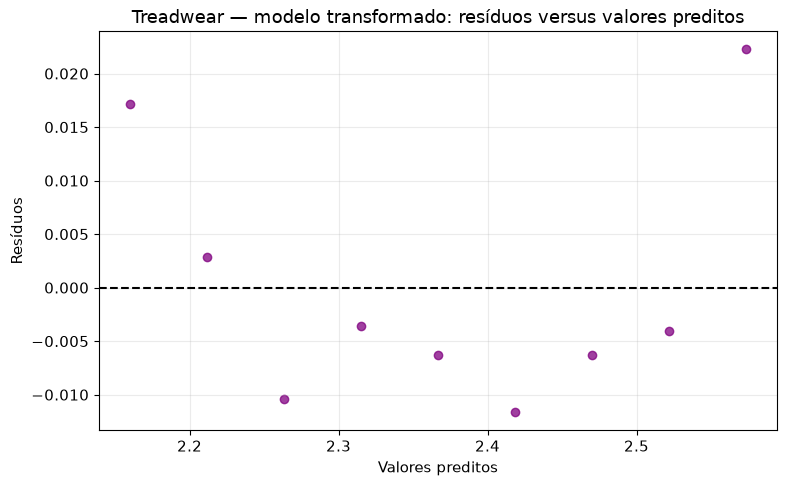

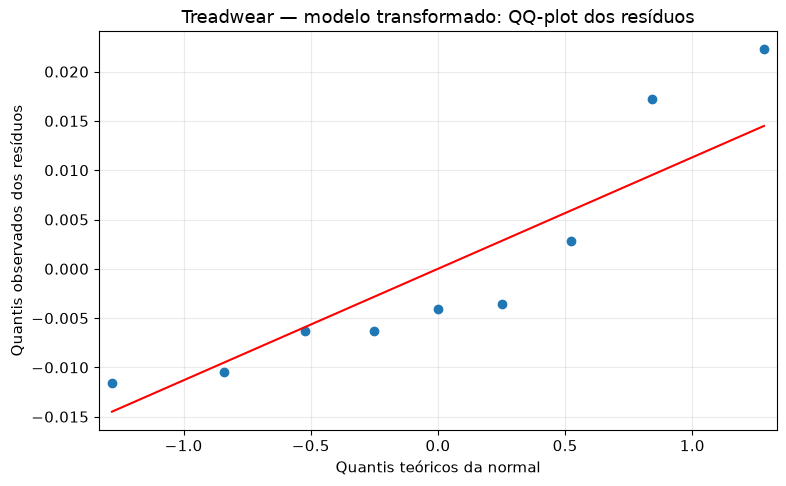

In [91]:
plotar_residuos(
    modelo_treadwear_t,
    "Treadwear — modelo transformado",
)

plotar_qq(
    modelo_treadwear_t,
    "Treadwear — modelo transformado",
)

#### Diagnóstico e avaliação LINE

O histograma foi omitido conforme a orientação do enunciado
para Treadwear, devido ao tamanho amostral de nove observações.

**L — Linearidade:** a transformação aproxima a associação
de uma reta, mas permanece curvatura nos resíduos. Portanto,
a inadequação da forma linear foi reduzida, mas não eliminada.

**I — Independência:** não pode ser confirmada pelos gráficos.
A transformação não modifica a estrutura da coleta nem estabelece
independência entre observações.

**N — Normalidade:** o QQ-plot apresenta desvios da reta de referência,
principalmente nos dois maiores resíduos positivos. Assim, há indícios
de inadequação da aproximação normal. Entretanto, o tamanho amostral
de nove observações limita a força dessa conclusão, e a curvatura
residual remanescente pode contribuir para esses desvios.

**E — Variância constante:** o tamanho amostral e a curvatura
remanescente limitam a avaliação. Não se deve considerar
a premissa satisfeita apenas porque os resíduos são numericamente
menores na escala logarítmica.

A transformação produz uma representação mais próxima da linearidade,
mas o diagnóstico ainda recomenda cautela na utilização do modelo.

### 3.3.2: Alligators

Foi aplicado logaritmo decimal às variáveis length e weight.

O modelo considerado é:

$$
\log_{10}(weight_i)
=\beta_0+\beta_1\log_{10}(length_i)+\varepsilon_i.
$$

Essa formulação permite representar uma relação de potência
entre comprimento e peso.

Ambas as variáveis são estritamente positivas, permitindo manter
as 25 observações.

,log10(length),log10(weight)
0,1.973128,2.113943
1,1.869232,1.707570
2,2.167317,2.806180
3,1.763428,1.447158
4,1.934498,1.903090


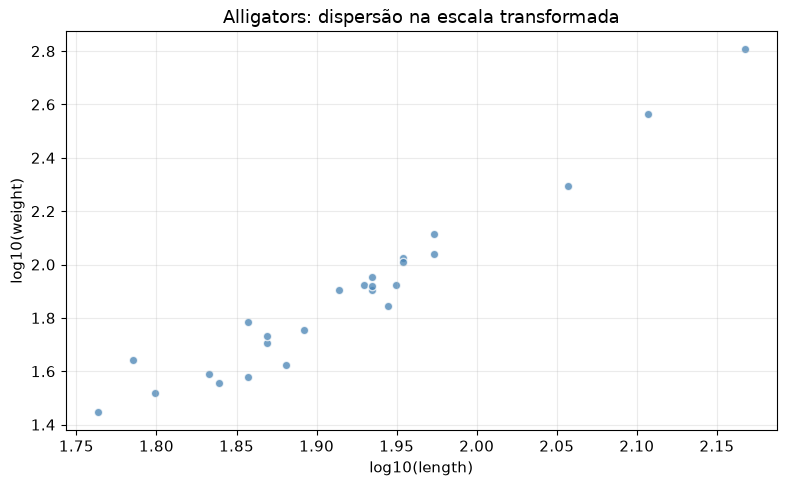

In [92]:
(
    df_alligators_t,
    modelo_alligators_t,
    x_alligators_t,
    y_alligators_t,
) = preparar_regressao_transformada(
    "Alligators",
    tx="log10",
    ty="log10",
)

display(df_alligators_t.head())

plotar_dispersao(
    df_alligators_t,
    x_alligators_t,
    y_alligators_t,
    "Alligators",
    escala="transformada",
)

A associação nas escalas logarítmicas apresenta uma tendência
positiva aproximadamente linear.

A transformação reduz a curvatura e a concentração visual
nos menores valores observadas na escala original.
Entretanto, ainda há dispersão em torno da tendência.

In [93]:
print(modelo_alligators_t.summary())

print(f"R²: {modelo_alligators_t.rsquared:.4f}")
print(f"R² ajustado: {modelo_alligators_t.rsquared_adj:.4f}")
print(
    "Erro padrão residual na escala log10: "
    f"{np.sqrt(modelo_alligators_t.mse_resid):.6f}"
)

                            OLS Regression Results                            
Dep. Variable:          log10(weight)   R-squared:                       0.945
Model:                            OLS   Adj. R-squared:                  0.943
Method:                 Least Squares   F-statistic:                     394.7
Date:                Tue, 13 Oct 2026   Prob (F-statistic):           5.59e-16
Time:                        05:13:47   Log-Likelihood:                 29.950
No. Observations:                  25   AIC:                            -55.90
Df Residuals:                      23   BIC:                            -53.46
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const            -4.4188      0.318    -13.907

#### Interpretação do ajuste

A equação estimada é:

$$
\widehat{\log_{10}(weight)}
=-4{,}418773+3{,}285993\,\log_{10}(length).
$$

O R² ajustado é aproximadamente 0,9425 na escala logarítmica.

O coeficiente angular pode ser interpretado como uma elasticidade:
para pequenas variações, um aumento de 1% no comprimento
está associado a um aumento aproximado de 3,29% na resposta
retrotransformada.

A retrotransformação da reta corresponde a:

$$
\widetilde{weight}
=10^{-4{,}418773}\,length^{3{,}285993}.
$$

Essa expressão representa uma relação de potência, mas não fornece
automaticamente a média aritmética condicional do peso original.

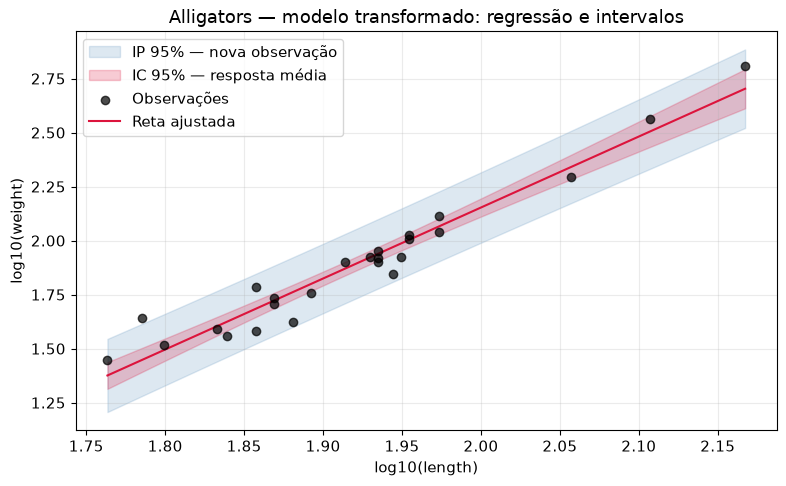

In [94]:
plotar_ajuste(
    df_alligators_t,
    modelo_alligators_t,
    x_alligators_t,
    y_alligators_t,
    "Alligators — modelo transformado",
)

O intervalo de confiança representa a incerteza sobre a média
de log10(weight) para cada valor de log10(length).

O intervalo de predição representa a incerteza sobre uma nova
observação individual de log10(weight).

Ambos estão na escala logarítmica. Interpretá-los como intervalos
diretos para o peso original exigiria retrotransformar seus limites.

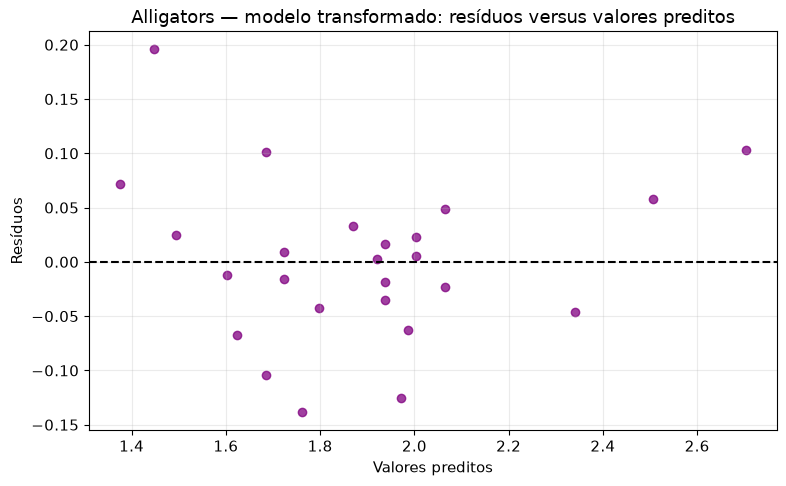

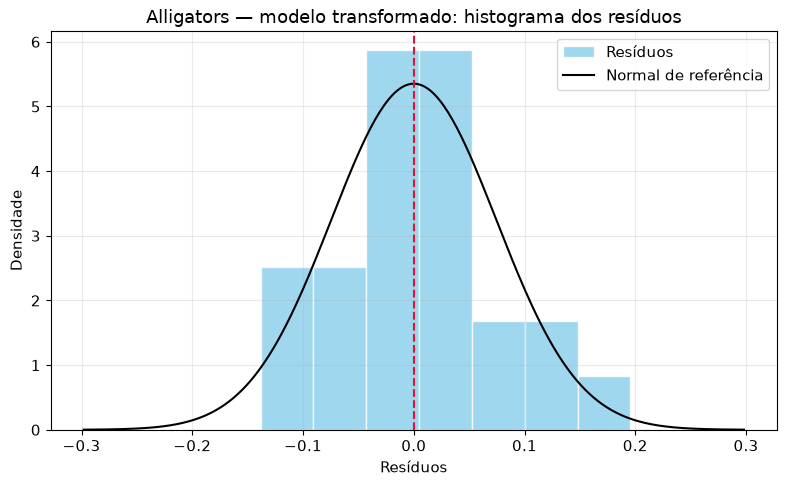

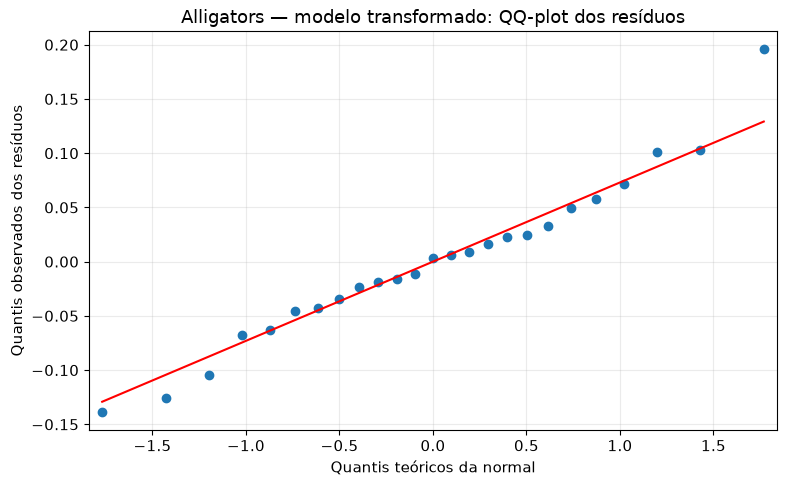

In [95]:
plotar_residuos(
    modelo_alligators_t,
    "Alligators — modelo transformado",
)

plotar_histograma(
    modelo_alligators_t,
    "Alligators — modelo transformado",
)

plotar_qq(
    modelo_alligators_t,
    "Alligators — modelo transformado",
)

#### Diagnóstico e avaliação LINE

**L — Linearidade:** a transformação log-log reduz a curvatura
sistemática observada no modelo original. A relação transformada
é mais compatível com uma representação linear.

**I — Independência:** permanece dependente do desenho da coleta.
Não pode ser estabelecida pela transformação ou pelos gráficos
apresentados.

**N — Normalidade:** a maior parte dos pontos do QQ-plot acompanha
aproximadamente a reta de referência. O histograma também apresenta
concentração central compatível com uma distribuição aproximadamente
normal. Há desvios nas caudas, especialmente no maior resíduo positivo,
mas não se observa uma inadequação tão acentuada quanto no modelo
original. A normalidade parece aproximadamente plausível, com ressalvas.

**E — Variância constante:** não se observa um formato de funil claro.
Entretanto, os menores valores preditos apresentam maior amplitude
residual, enquanto existem poucas observações na região superior.
Portanto, não há evidência visual conclusiva de heterocedasticidade,
mas também não é possível confirmar plenamente a variância constante.

O modelo log-log representa a associação de maneira mais adequada
que a reta na escala original quanto à forma da tendência.
Considerando os gráficos apresentados, o modelo log-log oferece
uma representação mais adequada da tendência. A normalidade
parece aproximadamente plausível, enquanto a variância constante
permanece inconclusiva e a independência depende do desenho da coleta.

### 3.3.3: ConcPatog

Foi aplicada raiz quadrada às duas concentrações.

O modelo considerado é:

$$
\sqrt{CPatog2_i}
=\beta_0+\beta_1\sqrt{CPatog1_i}+\varepsilon_i.
$$

A transformação comprime os valores elevados e permite manter
as observações com CPatog1 igual a zero.

Todas as 105 observações foram mantidas.

,raiz(CPatog1),raiz(CPatog2)
0,72.180330,85.276022
1,75.960516,113.137085
2,103.440804,423.083916
3,129.228480,435.889894
4,74.899933,287.880183


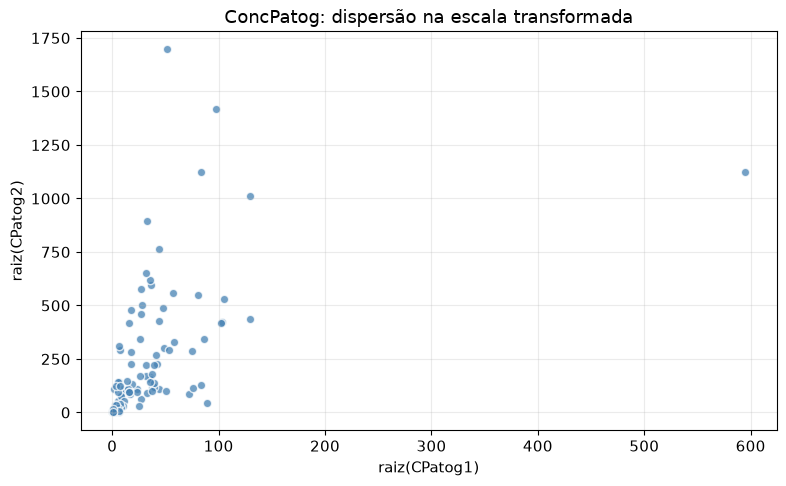

In [96]:
(
    df_patogenos_t,
    modelo_patogenos_t,
    x_patogenos_t,
    y_patogenos_t,
) = preparar_regressao_transformada(
    "ConcPatog",
    tx="raiz",
    ty="raiz",
)

display(df_patogenos_t.head())

plotar_dispersao(
    df_patogenos_t,
    x_patogenos_t,
    y_patogenos_t,
    "ConcPatog",
    escala="transformada",
)

A transformação reduz a concentração visual dos pontos
na região inferior do gráfico, permitindo observar melhor
a estrutura da associação.

Entretanto, permanecem grande dispersão e observações afastadas
da tendência. Assim, a transformação oferece uma melhora parcial,
sem produzir uma associação linear forte e uniforme.

In [97]:
print(modelo_patogenos_t.summary())

print(f"R²: {modelo_patogenos_t.rsquared:.4f}")
print(f"R² ajustado: {modelo_patogenos_t.rsquared_adj:.4f}")
print(
    "Erro padrão residual na escala de raiz quadrada: "
    f"{np.sqrt(modelo_patogenos_t.mse_resid):.6f}"
)

                            OLS Regression Results                            
Dep. Variable:          raiz(CPatog2)   R-squared:                       0.263
Model:                            OLS   Adj. R-squared:                  0.256
Method:                 Least Squares   F-statistic:                     36.79
Date:                Tue, 13 Oct 2026   Prob (F-statistic):           2.20e-08
Time:                        05:13:47   Log-Likelihood:                -733.83
No. Observations:                 105   AIC:                             1472.
Df Residuals:                     103   BIC:                             1477.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const           150.4407     29.568      5.088

#### Interpretação do ajuste

A equação estimada é:

$$
\widehat{\sqrt{CPatog2}}
=150{,}440730+2{,}499158\,\sqrt{CPatog1}.
$$

O R² ajustado é aproximadamente 0,2560, indicando que permanece
uma parcela elevada de variabilidade não explicada na escala
transformada.

O aumento de uma unidade em sqrt(CPatog1) está associado
a um aumento médio estimado de aproximadamente 2,50 unidades
em sqrt(CPatog2).

Essa interpretação não equivale a uma mudança constante
nas concentrações originais. Além disso, elevar a previsão
ao quadrado não fornece automaticamente a média condicional
de CPatog2.

O aumento do R² ajustado em relação ao modelo original
deve ser interpretado com cautela, pois a escala de Y mudou.
Ele não demonstra, isoladamente, maior acurácia preditiva
na escala original.

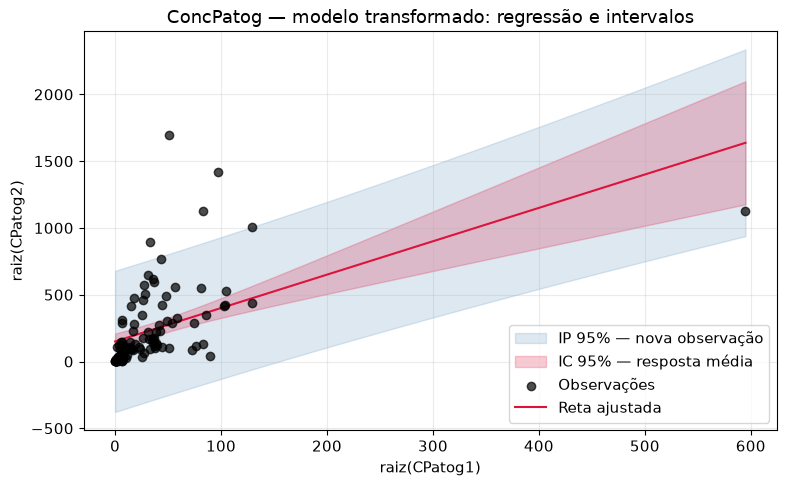

In [98]:
plotar_ajuste(
    df_patogenos_t,
    modelo_patogenos_t,
    x_patogenos_t,
    y_patogenos_t,
    "ConcPatog — modelo transformado",
)

O intervalo de confiança representa a incerteza sobre a média
de sqrt(CPatog2) para cada valor de sqrt(CPatog1).

O intervalo de predição representa a incerteza sobre uma nova
observação individual na escala de raiz quadrada.

A dispersão residual limita a precisão das previsões.
Eventuais limites negativos são incompatíveis com a resposta
transformada, que é não negativa, e evidenciam uma limitação
do modelo normal aditivo.

Esses limites não devem ser simplesmente elevados ao quadrado,
pois a função quadrado não é crescente em um intervalo
que inclua valores negativos.

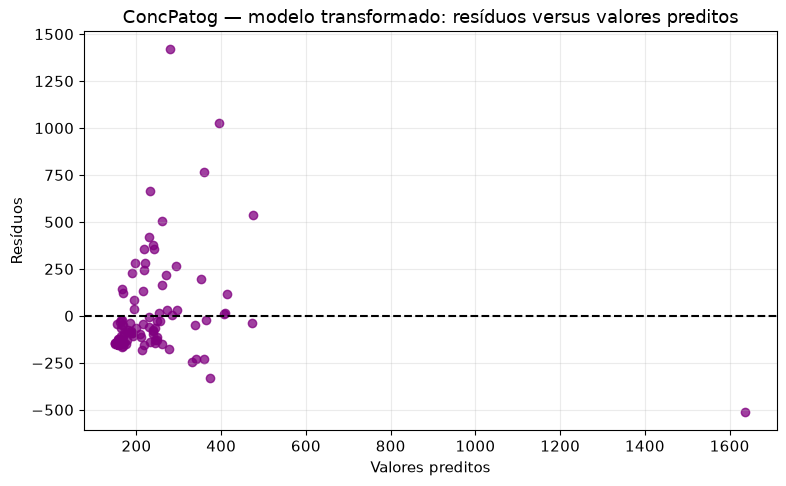

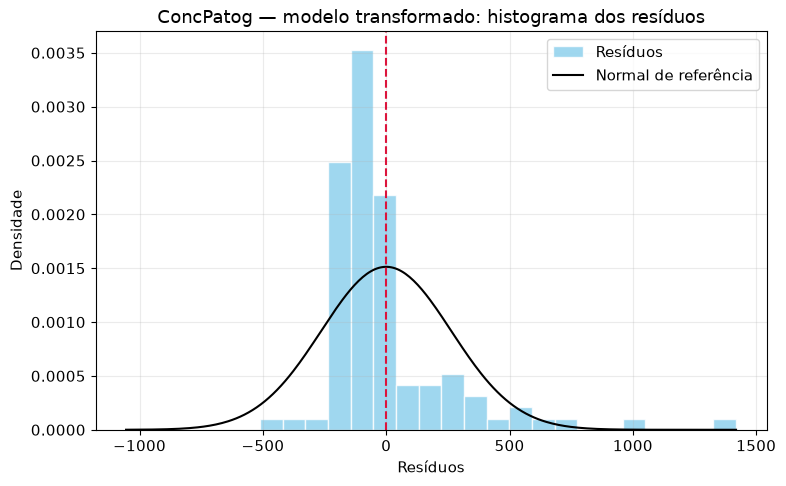

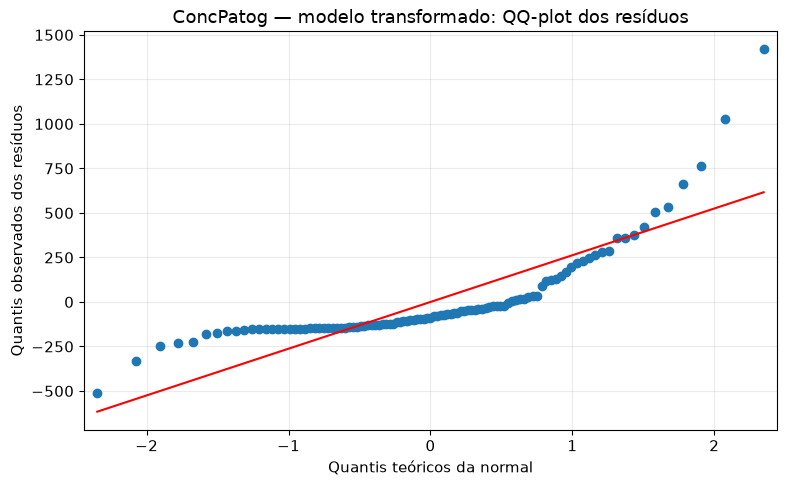

In [99]:
plotar_residuos(
    modelo_patogenos_t,
    "ConcPatog — modelo transformado",
)

plotar_histograma(
    modelo_patogenos_t,
    "ConcPatog — modelo transformado",
)

plotar_qq(
    modelo_patogenos_t,
    "ConcPatog — modelo transformado",
)

#### Diagnóstico e avaliação LINE

**L — Linearidade:** a transformação torna a estrutura dos dados
mais visível, mas permanecem grande dispersão e observações extremas.
A adequação da forma linear continua limitada.

**I — Independência:** não pode ser confirmada. A coleta em diferentes
estações, estágios e meses pode envolver dependências entre
observações relacionadas, não resolvidas pela transformação.

**N — Normalidade:** há evidências visuais fortes de violação.
O histograma apresenta assimetria acentuada à direita, e o QQ-plot
mostra desvios sistemáticos da reta, sobretudo na cauda superior.
Portanto, a transformação por raiz quadrada não resolveu
a inadequação da distribuição dos resíduos.

**E — Variância constante:** a dispersão residual é desigual entre
as regiões observadas, com resíduos positivos muito elevados
e uma observação isolada na maior previsão. Esse comportamento
levanta suspeita de heterocedasticidade. Entretanto, a concentração
dos dados nas menores previsões e a escassez de pontos na região
superior impedem uma avaliação conclusiva de sua forma.

A raiz quadrada em ambas as variáveis oferece uma representação
mais informativa que a escala original, mas o poder explicativo
permanece limitado. Não há base suficiente para afirmar que
o modelo estime CPatog2 com razoável acurácia apenas a partir
dos resultados apresentados.